# Notebook 09: Hierarchical Cascade vs. Improved Flat 34-Class IDS Evaluation (Track 2)

## What This Notebook Investigates (Plain-English Roadmap)
In Track 1, we established leakage-free, non-overlapping CICIoT2023 evaluation splits (`Train`, `Validation`, `Internal Test`, and unseen `Cross-Capture Clean`) and showed that a realistic 34-class flat LightGBM baseline (**E1**) gets **72.65% Accuracy / 0.6145 Macro-F1** on Internal Test.

In **Track 2**, we tested our November 4 hypothesis:
> *Instead of asking one model to separate all 34 classes simultaneously, does a **3-Stage Hierarchical Cascade (E2)** (Binary filter -> Flood vs. Non-Flood router -> 16-class Flood specialist & 17-class Non-Flood specialist) outperform a flat classifier?*

Crucially, to make a fair scientific comparison rather than comparing against an outdated baseline, we also built **E4**: a single flat 34-class classifier upgraded with the **same tree capacity (`num_leaves=63, n_estimators=150`) and gentler `sqrt_balanced` class weighting** used inside E2's specialists.

### Key Questions Answered With Visuals Below
1. **What are the exact splits, ratios, and Cross-Capture composition?** (Why `Merged26..40` behaves differently from `Merged01..25`.)
2. **Why did validation tuning matter so much?** (Why Stage 1 at default `0.50` misses `11.6%` of attacks, and how `sqrt_balanced` weights reshape flat E4.)
3. **E1 vs. E2 vs. E4 Showdown:** Who actually wins on Accuracy, Macro-F1, Minority Attacks, Cross-Capture generalization, and single-flow latency?
4. **Where do the remaining errors come from?** (Proof that Flood-vs-Non-Flood routing is already ~99.98% solved, while **flow-feature twins like `DDOS-TCP_FLOOD` vs. `DOS-TCP_FLOOD` and `RECON-OSSCAN` vs. `BENIGN`** explain the shared ~75% ceiling.)

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

# Resolve repo root cleanly from notebooks/ or repo root
CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

TRACK1_PARTITIONS = REPO_ROOT / "track1_dataset_evaluation" / "data" / "partitions"
HIER_RESULTS = REPO_ROOT / "track2_ids_engineering" / "hierarchical_ids" / "results"
CM_DIR = HIER_RESULTS / "confusion_matrices"

import sys
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from track1_dataset_evaluation.src.config import FEATURE_COLUMNS, THIRTY_FOUR_CLASSES
from track2_ids_engineering.hierarchical_ids.src.data_utils import (
    FLOOD_CLASSES,
    MINORITY_ATTACK_CLASSES,
    NON_FLOOD_CLASSES,
)

# Short readable display names focusing on our main E1 vs E2 vs E4 study
ARCH_LABELS = {
    "E1_Flat34_LGBM_Balanced": "E1: Flat Track1 (Balanced)",
    "E1_Ref_Unweighted_Track1": "E1-Ref: Flat Track1 (Unweighted)",
    "E2_Cascade_Default_T050": "E2: Cascade Default (T=0.50)",
    "E2_Cascade_ValTuned": "E2: Cascade Tuned (T=0.15)",
    "E4_Improved_Flat34 (E4_LGBM_Leaves63_Sqrt)": "E4: Improved Flat (L63 Sqrt)",
}
MAIN_ORDER = [
    "E1_Flat34_LGBM_Balanced",
    "E2_Cascade_Default_T050",
    "E2_Cascade_ValTuned",
    "E4_Improved_Flat34 (E4_LGBM_Leaves63_Sqrt)",
]
PALETTE = {
    "E1: Flat Track1 (Balanced)": "#64748B",
    "E2: Cascade Default (T=0.50)": "#F59E0B",
    "E2: Cascade Tuned (T=0.15)": "#2563EB",
    "E4: Improved Flat (L63 Sqrt)": "#10B981",
}

print(f"Repository Root : {REPO_ROOT}")
print(f"Results Folder  : {HIER_RESULTS}")
print(f"Feature Count   : {len(FEATURE_COLUMNS)} features | Classes: {len(THIRTY_FOUR_CLASSES)} ({len(FLOOD_CLASSES)} Flood + {len(NON_FLOOD_CLASSES)} Non-Flood + 1 Benign)")

Repository Root : C:\Users\priya\Downloads\capstone
Results Folder  : C:\Users\priya\Downloads\capstone\track2_ids_engineering\hierarchical_ids\results
Feature Count   : 39 features | Classes: 34 (16 Flood + 17 Non-Flood + 1 Benign)


---
## 1. Understanding Our Splits: Train / Val / Internal Test vs. Cross-Capture

### Where Each Dataset Came From
1. **Internal 70 / 15 / 15 Split (`501,098` clean flows from `Merged01.csv`–`Merged25.csv`)**:
   - Track 1 took `sample_stratified.csv` (529,562 rows sampled from the first 25 capture files, capped at 25k/attack and 50k benign), removed **28,464 exact duplicates** (`501,098` remaining), and split by feature-hash group so **zero identical flow feature vectors span splits**:
     - **Train**: `350,821` (**70.01%**)
     - **Validation**: `75,172` (**15.00%**)
     - **Internal Test**: `75,105` (**14.99%**)
2. **Cross-Capture Clean (`57,280` unseen flows from `Merged26.csv`–`Merged40.csv`)**:
   - **Not** part of the 70/15/15 split — it is a separate **later-file holdout** extracted from 15 unseen capture CSV files (`Merged26`–`Merged40`), capped at **2,000 rows per attack and 5,000 Benign**, with any vectors overlapping Train/Val/Test removed (`57,280` left).
   - Notice the catch below: because big classes are capped at `2,000` while rare classes keep up to all available rows, the **8 minority attack classes jump from `2.58%` in Test to `14.64%` in Cross-Capture (~5.67x denser!)**.

,Split,Total,Benign %,Flood (16) %,NonFlood Major (9) %,Minority (8) %
0,Train (Merged01-25),350821,7.94,53.96,35.51,2.60
1,Val (Merged01-25),75172,8.10,54.22,35.23,2.45
2,Test (Merged01-25),75105,8.01,53.94,35.47,2.58
3,Cross-Capture (Merged26-40),57280,8.70,45.82,30.84,14.64


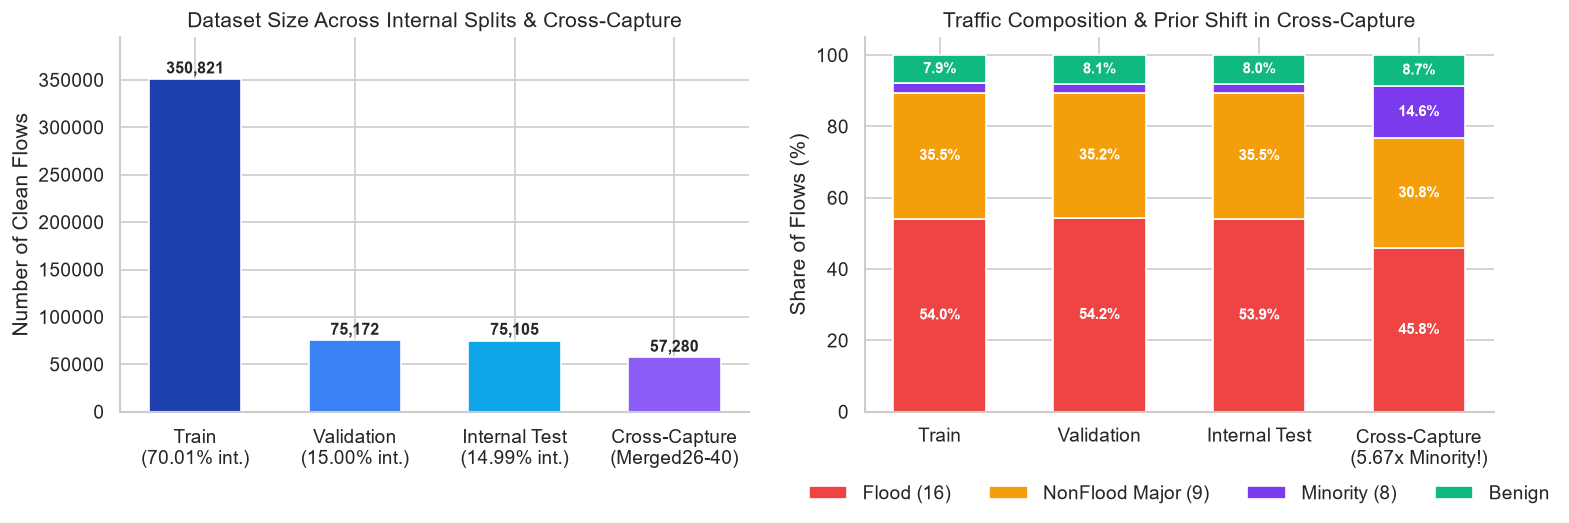

In [2]:
with open(TRACK1_PARTITIONS / "partition_metadata.json") as f:
    part_meta = json.load(f)
with open(TRACK1_PARTITIONS / "cross_capture_metadata.json") as f:
    cross_meta = json.load(f)

split_stats = pd.DataFrame([
    {"Split": "Train (Merged01-25)", "Total": 350821, "Benign": 27855, "Flood (16)": 189288, "NonFlood Major (9)": 133678 - 9108, "Minority (8)": 9108},
    {"Split": "Val (Merged01-25)", "Total": 75172, "Benign": 6086, "Flood (16)": 40760, "NonFlood Major (9)": 28326 - 1844, "Minority (8)": 1844},
    {"Split": "Test (Merged01-25)", "Total": 75105, "Benign": 6019, "Flood (16)": 40511, "NonFlood Major (9)": 28575 - 1939, "Minority (8)": 1939},
    {"Split": "Cross-Capture (Merged26-40)", "Total": 57280, "Benign": 4982, "Flood (16)": 26247, "NonFlood Major (9)": 26051 - 8384, "Minority (8)": 8384},
])
for col in ["Benign", "Flood (16)", "NonFlood Major (9)", "Minority (8)"]:
    split_stats[f"{col} %"] = (split_stats[col] / split_stats["Total"] * 100).round(2)

display(split_stats[["Split", "Total", "Benign %", "Flood (16) %", "NonFlood Major (9) %", "Minority (8) %"]])

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

# Left: Absolute flow counts
x = np.arange(len(split_stats))
bars = axes[0].bar(x, split_stats["Total"], color=["#1E40AF", "#3B82F6", "#0EA5E9", "#8B5CF6"], width=0.58)
axes[0].set_xticks(x)
axes[0].set_xticklabels(["Train\n(70.01% int.)", "Validation\n(15.00% int.)", "Internal Test\n(14.99% int.)", "Cross-Capture\n(Merged26-40)"])
axes[0].set_ylabel("Number of Clean Flows")
axes[0].set_title("Dataset Size Across Internal Splits & Cross-Capture")
for b, tot in zip(bars, split_stats["Total"]):
    axes[0].text(b.get_x() + b.get_width() / 2, tot + 6000, f"{tot:,}", ha="center", fontweight="bold", fontsize=9.5)
axes[0].set_ylim(0, 395000)

# Right: Stacked composition % showing 5.67x minority shift in Cross-Capture
cols_pct = ["Flood (16) %", "NonFlood Major (9) %", "Minority (8) %", "Benign %"]
colors_pct = ["#EF4444", "#F59E0B", "#7C3AED", "#10B981"]
bottom = np.zeros(len(split_stats))
for col, clr in zip(cols_pct, colors_pct):
    vals = split_stats[col].to_numpy()
    axes[1].bar(x, vals, bottom=bottom, label=col.replace(" %", ""), color=clr, width=0.58)
    for i, v in enumerate(vals):
        if v >= 6.0:
            axes[1].text(x[i], bottom[i] + v / 2, f"{v:.1f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=9)
    bottom += vals

axes[1].set_xticks(x)
axes[1].set_xticklabels(["Train", "Validation", "Internal Test", "Cross-Capture\n(5.67x Minority!)"])
axes[1].set_ylabel("Share of Flows (%)")
axes[1].set_title("Traffic Composition & Prior Shift in Cross-Capture")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, frameon=False)
plt.tight_layout()
plt.show()

---
## 2. Why Validation Tuning Mattered (Stage 1 Threshold & Flat Weighting Ablations)

Before touching Test or Cross-Capture, we tuned everything strictly on **Validation (`N = 75,172`)**:
1. **Left Chart**: Track 1's Stage 1 binary models were trained with `class_weight="balanced"` (~11.6x weight on Benign). At default `0.50`, Stage 1 acts overly cautious toward Benign and **drops ~11.4% of real attacks on Validation** right at the door! Lowering `tau_att` to `0.15` fixes most missed attacks and pushes E2 Validation Macro-F1 from **0.622 → 0.639**.
2. **Right Chart**: On the flat 34-class model (E4), switching from harsh inverse-frequency `balanced` weighting (`0.6142` Macro-F1) to gentler `sqrt_balanced` weighting (`0.6337`) plus `num_leaves=63, n_estimators=150` (`0.6358`) closes almost the entire gap with the cascade — without needing 3 separate stages!

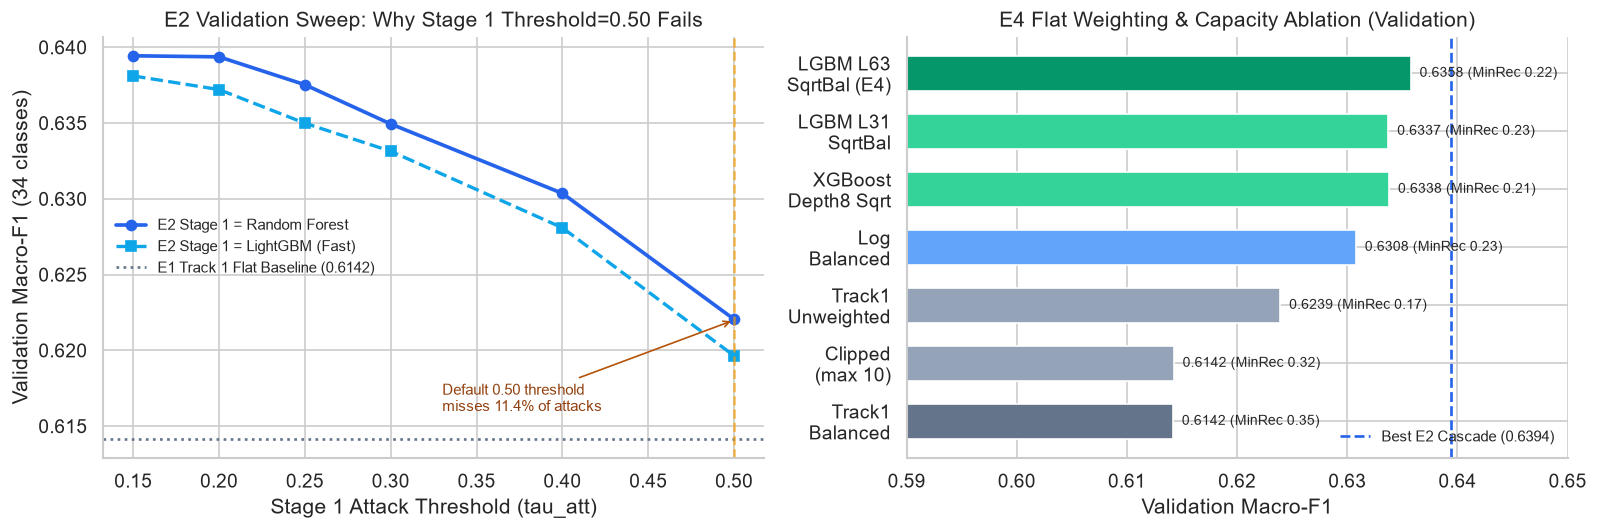

In [3]:
df_sweeps = pd.read_csv(HIER_RESULTS / "val_e2_e3_sweeps.csv")
df_e4 = pd.read_csv(HIER_RESULTS / "val_e4_candidates.csv")

# Filter E2 sweep for our best router+specialist setup (`bin_rf + cat7_sqrt`, flood tau 0.40) and LGBM S1 comparison
e2_rf_curve = df_sweeps[(df_sweeps["s1"] == "bin_rf") & (df_sweeps["s2"] == "cat7_sqrt") & (df_sweeps["f_tau"] == "0.40")].sort_values("tau_att")
e2_lgb_curve = df_sweeps[(df_sweeps["s1"] == "bin_lgbm") & (df_sweeps["s2"] == "cat7_sqrt") & (df_sweeps["f_tau"] == "0.40")].sort_values("tau_att")

# Raw (T=1.0, tau_prior=0) flat E4 candidates ordered cleanly
e4_order = [
    ("E4_LGBM_Balanced_Track1", "Track1\nBalanced"),
    ("E4_LGBM_Clipped10", "Clipped\n(max 10)"),
    ("E4_LGBM_Unweighted_Track1", "Track1\nUnweighted"),
    ("E4_LGBM_LogBalanced", "Log\nBalanced"),
    ("E4_XGB_Depth8_Sqrt", "XGBoost\nDepth8 Sqrt"),
    ("E4_LGBM_SqrtBalanced", "LGBM L31\nSqrtBal"),
    ("E4_LGBM_Leaves63_Sqrt", "LGBM L63\nSqrtBal (E4)"),
]
e4_raw = df_e4[df_e4["candidate_id"].isin([k for k, _ in e4_order])].set_index("candidate_id").loc[[k for k, _ in e4_order]]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

axes[0].plot(e2_rf_curve["tau_att"], e2_rf_curve["macro_f1"], "o-", color="#2563EB", lw=2.2, label="E2 Stage 1 = Random Forest")
axes[0].plot(e2_lgb_curve["tau_att"], e2_lgb_curve["macro_f1"], "s--", color="#0EA5E9", lw=2.0, label="E2 Stage 1 = LightGBM (Fast)")
axes[0].axhline(0.61418, color="#64748B", ls=":", lw=1.6, label="E1 Track 1 Flat Baseline (0.6142)")
axes[0].axvline(0.50, color="#F59E0B", ls="--", alpha=0.7)
axes[0].annotate("Default 0.50 threshold\nmisses 11.4% of attacks", xy=(0.50, 0.622), xytext=(0.33, 0.616),
                 arrowprops=dict(arrowstyle="->", color="#B45309"), fontsize=8.8, color="#92400E")
axes[0].set_xlabel("Stage 1 Attack Threshold (tau_att)")
axes[0].set_ylabel("Validation Macro-F1 (34 classes)")
axes[0].set_title("E2 Validation Sweep: Why Stage 1 Threshold=0.50 Fails")
axes[0].legend(frameon=False, fontsize=8.8)

y_pos = np.arange(len(e4_order))
bar_colors = ["#64748B", "#94A3B8", "#94A3B8", "#60A5FA", "#34D399", "#34D399", "#059669"]
bars = axes[1].barh(y_pos, e4_raw["macro_f1"], color=bar_colors, height=0.6)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([lbl for _, lbl in e4_order])
axes[1].set_xlabel("Validation Macro-F1")
axes[1].set_xlim(0.59, 0.65)
axes[1].axvline(0.63944, color="#2563EB", ls="--", lw=1.6, label="Best E2 Cascade (0.6394)")
for b, val, mrec in zip(bars, e4_raw["macro_f1"], e4_raw["minority_macro_recall"]):
    axes[1].text(val + 0.0008, b.get_y() + b.get_height() / 2, f"{val:.4f} (MinRec {mrec:.2f})", va="center", fontsize=8.5)
axes[1].set_title("E4 Flat Weighting & Capacity Ablation (Validation)")
axes[1].legend(loc="lower right", frameon=False, fontsize=8.8)

plt.tight_layout()
plt.show()

---
## 3. Main Results: E1 vs. E2 vs. E4 Across Test (`75,105`) and Cross-Capture (`57,280`)

Notice the real takeaway across every bar below:
- **E2 Tuned** beats Track 1 **E1** clearly on Internal Test (`0.6361` vs `0.6145` Macro-F1; `75.03%` vs `72.65%` Accuracy).
- **E4 Improved Flat** (`Leaves63 + SqrtBalanced`) **essentially ties E2 on Macro-F1 (`0.6352` Test / `0.6441` Cross)** while **winning highest Accuracy & MCC on both Test (`75.37%`) and Cross (`70.72%`)**, **running only 1 model per flow (~4.15 ms vs ~53.3 ms with Stage 1 RF)**!
- Why does old **E1** jump on **Cross Macro-F1** (`0.6498`)? Because `balanced` weighting over-predicts rare classes (giving ~34-35% minority recall everywhere), which crushes precision on natural Test (`0.1624` Minority F1) but scores higher when Cross-Capture inflates rare classes 5.67x!

,Split,Arch,accuracy,macro_f1,mcc,flood_macro_f1,non_flood_macro_f1,minority_macro_f1,minority_macro_recall,benign_recall,attack_to_benign_fnr,mean_executions_per_flow,single_latency_p50_us,model_size_mb
0,Val,E1: Flat Track1 (Balanced),0.7246,0.6142,0.7149,0.7931,0.4415,0.1656,0.3513,0.6584,0.0224,1.0000,NaN,11.331
1,Val,E2: Cascade Default (T=0.50),0.7352,0.6196,0.7281,0.7962,0.4548,0.2143,0.1524,0.9727,0.1143,2.6324,NaN,35.566
2,Val,E2: Cascade Tuned (T=0.15),0.7491,0.6394,0.7392,0.7962,0.4883,0.2426,0.2253,0.7420,0.0332,2.8187,NaN,46.996
3,Val,E4: Improved Flat (L63 Sqrt),0.7513,0.6358,0.7416,0.7948,0.4812,0.2271,0.2194,0.7843,0.0351,1.0000,NaN,33.895
4,Test,E1: Flat Track1 (Balanced),0.7265,0.6145,0.7170,0.7943,0.4410,0.1624,0.3360,0.6571,0.0220,1.0000,3426.65,11.331
5,Test,E2: Cascade Default (T=0.50),0.7359,0.6185,0.7290,0.7971,0.4520,0.2115,0.1519,0.9738,0.1156,2.6312,7884.05,35.566
6,Test,E2: Cascade Tuned (T=0.15),0.7504,0.6361,0.7405,0.7971,0.4810,0.2264,0.2094,0.7387,0.0329,2.8210,53297.75,46.996
7,Test,E4: Improved Flat (L63 Sqrt),0.7537,0.6352,0.7440,0.7960,0.4788,0.2196,0.2063,0.7863,0.0344,1.0000,4154.25,33.895
8,Cross,E1: Flat Track1 (Balanced),0.6964,0.6498,0.6861,0.8084,0.4994,0.3142,0.3495,0.6552,0.0288,1.0000,3843.95,11.331
9,Cross,E2: Cascade Default (T=0.50),0.6861,0.6213,0.6818,0.8087,0.4518,0.2294,0.1489,0.9731,0.1784,2.5050,8364.45,35.566


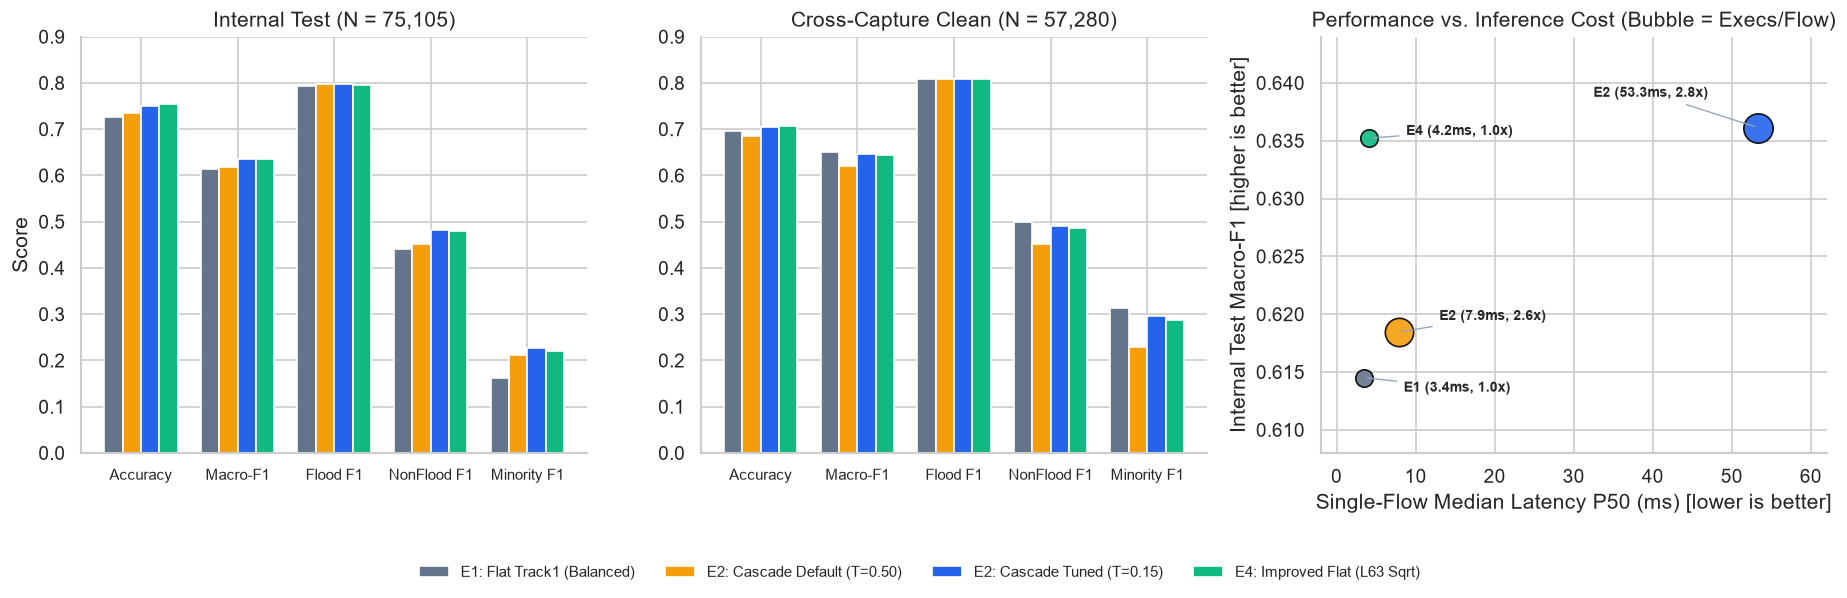

In [4]:
df_val = pd.read_csv(HIER_RESULTS / "final_comparison_val.csv")
df_test = pd.read_csv(HIER_RESULTS / "final_comparison_test.csv")
df_cross = pd.read_csv(HIER_RESULTS / "final_comparison_cross.csv")

def prep_table(df, split_name):
    sub = df[df["architecture"].isin(MAIN_ORDER)].copy()
    sub["Arch"] = sub["architecture"].map(ARCH_LABELS)
    sub["Split"] = split_name
    return sub

df_main_all = pd.concat([prep_table(df_val, "Val"), prep_table(df_test, "Test"), prep_table(df_cross, "Cross")], ignore_index=True)

summary_cols = [
    "Split", "Arch", "accuracy", "macro_f1", "mcc",
    "flood_macro_f1", "non_flood_macro_f1", "minority_macro_f1", "minority_macro_recall",
    "benign_recall", "attack_to_benign_fnr", "mean_executions_per_flow", "single_latency_p50_us", "model_size_mb",
]
display(df_main_all[summary_cols].round(4))

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.8))

# Panel 1: Internal Test Metrics
t_sub = prep_table(df_test, "Test").set_index("architecture").loc[MAIN_ORDER]
metrics_list = [("accuracy", "Accuracy"), ("macro_f1", "Macro-F1"), ("flood_macro_f1", "Flood F1"), ("non_flood_macro_f1", "NonFlood F1"), ("minority_macro_f1", "Minority F1")]
x_m = np.arange(len(metrics_list))
w = 0.19
for i, arch in enumerate(MAIN_ORDER):
    lbl = ARCH_LABELS[arch]
    vals = [t_sub.loc[arch, k] for k, _ in metrics_list]
    axes[0].bar(x_m + (i - 1.5) * w, vals, width=w, label=lbl, color=PALETTE[lbl])
axes[0].set_xticks(x_m)
axes[0].set_xticklabels([n for _, n in metrics_list], fontsize=8.8)
axes[0].set_ylim(0.0, 0.90)
axes[0].set_title("Internal Test (N = 75,105)")
axes[0].set_ylabel("Score")

# Panel 2: Cross-Capture Metrics
c_sub = prep_table(df_cross, "Cross").set_index("architecture").loc[MAIN_ORDER]
for i, arch in enumerate(MAIN_ORDER):
    lbl = ARCH_LABELS[arch]
    vals = [c_sub.loc[arch, k] for k, _ in metrics_list]
    axes[1].bar(x_m + (i - 1.5) * w, vals, width=w, label=lbl, color=PALETTE[lbl])
axes[1].set_xticks(x_m)
axes[1].set_xticklabels([n for _, n in metrics_list], fontsize=8.8)
axes[1].set_ylim(0.0, 0.90)
axes[1].set_title("Cross-Capture Clean (N = 57,280)")

# Panel 3: Speed vs Macro-F1 Pareto on Internal Test
label_offsets = {
    "E1_Flat34_LGBM_Balanced": (8.5, 0.6133),
    "E2_Cascade_Default_T050": (13.0, 0.6195),
    "E2_Cascade_ValTuned": (32.5, 0.6388),
    "E4_Improved_Flat34 (E4_LGBM_Leaves63_Sqrt)": (8.8, 0.6355),
}
for arch in MAIN_ORDER:
    lbl = ARCH_LABELS[arch]
    lat_ms = t_sub.loc[arch, "single_latency_p50_us"] / 1000.0
    mf1 = t_sub.loc[arch, "macro_f1"]
    execs = t_sub.loc[arch, "mean_executions_per_flow"]
    axes[2].scatter(lat_ms, mf1, s=execs * 110, color=PALETTE[lbl], edgecolor="black", alpha=0.9, zorder=3)
    tx, ty = label_offsets[arch]
    axes[2].annotate(f"{lbl.split(':')[0]} ({lat_ms:.1f}ms, {execs:.1f}x)", (lat_ms, mf1),
                     xytext=(tx, ty), fontsize=8.4, fontweight="bold",
                     arrowprops=dict(arrowstyle="-", color="#94A3B8", lw=0.8))
axes[2].set_xlabel("Single-Flow Median Latency P50 (ms) [lower is better]")
axes[2].set_ylabel("Internal Test Macro-F1 [higher is better]")
axes[2].set_title("Performance vs. Inference Cost (Bubble = Execs/Flow)")
axes[2].set_xlim(-2, 62)
axes[2].set_ylim(0.608, 0.644)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.05), ncol=4, frameon=False, fontsize=9)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

---
## 4. Where Did Errors Happen? (Stage Diagnostics & Within-Family Collisions)

Two huge discoveries live in the error breakdown below:
1. **Cross-family routing (Flood ↔ Non-Flood) is practically zero error (~0.06% of flows!)**:
   - On Internal Test (`75,105` flows), **E2 Cascade** only misrouted **50** flows between Flood and Non-Flood (`9` + `41`), and **E4 Flat** only crossed that boundary on **46** flows (`11` + `35`).
   - So splitting Flood vs. Non-Flood into two separate models wasn't solving a real bottleneck — even one flat LightGBM tree ensemble learns that split easily.
2. **Why `DDOS-*` vs. `DOS-*` classes look nearly identical in this dataset**:
   - In real networks, **DDoS** = *many distributed attacker bots flooding a victim*, while **DoS** = *one attacker machine flooding a victim*. CICIoT2023 recorded those scenarios separately in the lab and stamped the scenario name as the label.
   - **However**, the 39 exported tabular flow features (`Header_Length`, `Rate`, TCP flags like `syn_flag_number`, packet sizes `Tot sum`, `AVG`, `IAT`, etc.) **strip out IP addresses and have no count of how many distinct attacker IPs are sending traffic**.
   - As the right chart shows, **the exact same `DDOS-SYN ↔ SYNONYMOUSIP`, `DDOS-TCP ↔ DOS-TCP`, and `DOS-UDP ↔ DDOS-UDP` pairs dominate the error bars for BOTH E2 Cascade and E4 Flat!**

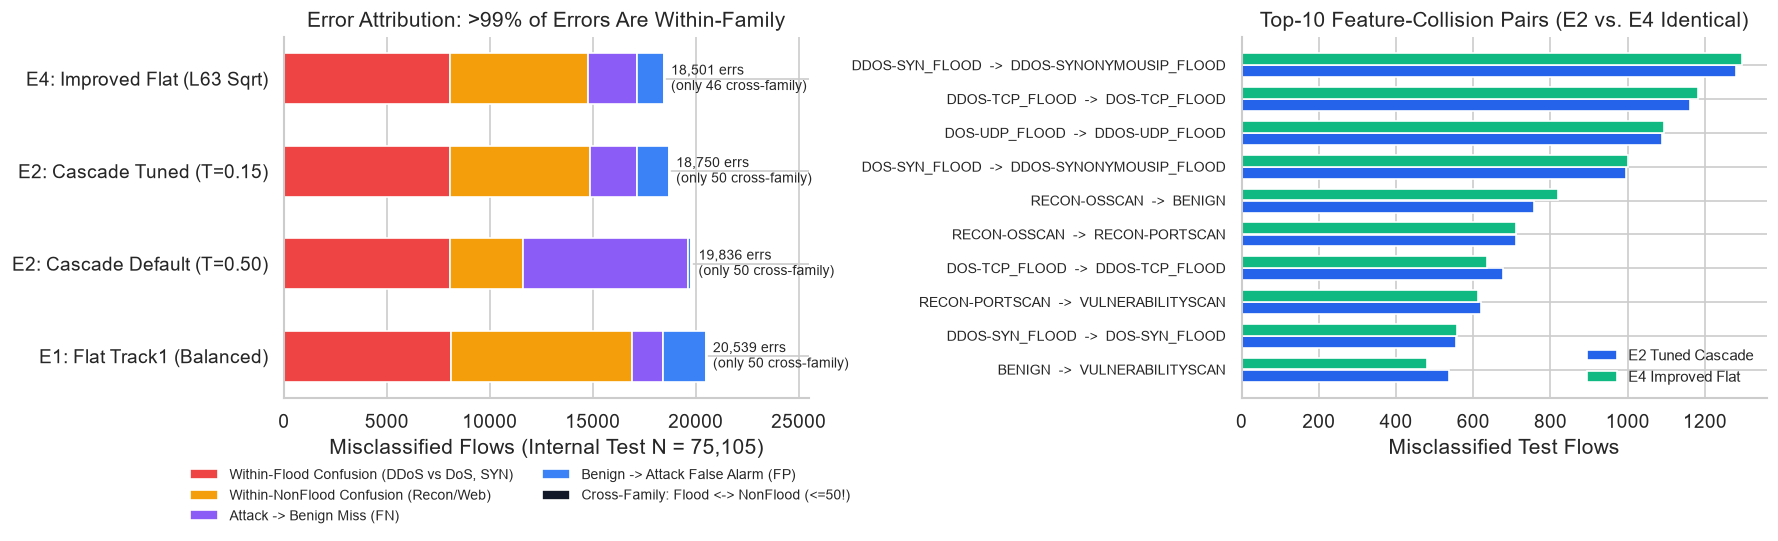

In [5]:
df_err_test = pd.read_csv(HIER_RESULTS / "error_attribution_test.csv")
df_err_sub = df_err_test[df_err_test["architecture"].isin(MAIN_ORDER)].set_index("architecture").loc[MAIN_ORDER]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# Left: Stacked Horizontal Bar of Error Buckets
err_cols = [
    ("within_flood_confusion", "Within-Flood Confusion (DDoS vs DoS, SYN)", "#EF4444"),
    ("within_nonflood_confusion", "Within-NonFlood Confusion (Recon/Web)", "#F59E0B"),
    ("attack_to_benign_fn", "Attack -> Benign Miss (FN)", "#8B5CF6"),
    ("benign_to_attack_fp", "Benign -> Attack False Alarm (FP)", "#3B82F6"),
    ("flood_routed_to_nonflood", "Cross-Family: Flood <-> NonFlood (<=50!)", "#111827"),
]
y_idx = np.arange(len(MAIN_ORDER))
left = np.zeros(len(MAIN_ORDER))
for col, label, clr in err_cols:
    vals = df_err_sub[col].to_numpy()
    if col == "flood_routed_to_nonflood":
        vals = vals + df_err_sub["nonflood_routed_to_flood"].to_numpy()
    axes[0].barh(y_idx, vals, left=left, label=label, color=clr, height=0.55)
    left += vals
for i, tot in enumerate(df_err_sub["total_errors"]):
    cross_err = int(df_err_sub.iloc[i]["flood_routed_to_nonflood"] + df_err_sub.iloc[i]["nonflood_routed_to_flood"])
    axes[0].text(tot + 300, y_idx[i], f"{tot:,} errs\n(only {cross_err} cross-family)", va="center", fontsize=8.5)
axes[0].set_yticks(y_idx)
axes[0].set_yticklabels([ARCH_LABELS[a] for a in MAIN_ORDER])
axes[0].set_xlim(0, 25500)
axes[0].set_xlabel("Misclassified Flows (Internal Test N = 75,105)")
axes[0].set_title("Error Attribution: >99% of Errors Are Within-Family")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.45, -0.16), ncol=2, frameon=False, fontsize=8.5)

# Right: Top-10 Confusion Pairs comparing E2 vs E4 directly from saved confusion matrices
cm_e4 = np.load(CM_DIR / "cm_E4_Improved_Flat34_E4_LGBM_Leaves63_Sqrt_test.npy").copy()
cm_e2 = np.load(CM_DIR / "cm_E2_Cascade_ValTuned_test.npy").copy()
np.fill_diagonal(cm_e4, 0)
np.fill_diagonal(cm_e2, 0)

top_idx = np.argsort(cm_e4.ravel())[::-1][:10]
pair_labels, e4_counts, e2_counts = [], [], []
for idx in top_idx[::-1]:
    i, j = divmod(int(idx), len(THIRTY_FOUR_CLASSES))
    pair_labels.append(f"{THIRTY_FOUR_CLASSES[i]}  ->  {THIRTY_FOUR_CLASSES[j]}")
    e4_counts.append(int(cm_e4[i, j]))
    e2_counts.append(int(cm_e2[i, j]))

yp = np.arange(len(pair_labels))
axes[1].barh(yp - 0.18, e2_counts, height=0.35, color="#2563EB", label="E2 Tuned Cascade")
axes[1].barh(yp + 0.18, e4_counts, height=0.35, color="#10B981", label="E4 Improved Flat")
axes[1].set_yticks(yp)
axes[1].set_yticklabels(pair_labels, fontsize=8.2)
axes[1].set_xlabel("Misclassified Test Flows")
axes[1].set_title("Top-10 Feature-Collision Pairs (E2 vs. E4 Identical)")
axes[1].legend(loc="lower right", frameon=False, fontsize=8.8)

plt.tight_layout()
plt.show()

---
## 5. Minority Attack Analysis (`8 Rare Classes < 1% of Train`) & Practical Takeaway

Notice the **Precision vs. Recall** trade-off on the 8 rarest attacks (`UPLOADING_ATTACK`, `RECON-PINGSWEEP`, `BACKDOOR_MALWARE`, `XSS`, `COMMANDINJECTION`, `SQLINJECTION`, `BROWSERHIJACKING`, `DICTIONARYBRUTEFORCE`):
- **E1 (Balanced)** gets the highest **Recall** (~`0.34`), **but its precision collapses** from false alarms (e.g., `651` `VULNERABILITYSCAN` rows mislabeled `SQLINJECTION`), dragging **Test Minority F1 down to `0.1624`**.
- **E2 Tuned (`0.2264`) & E4 (`0.2196`)** win **Test Minority F1**, cleanly raising practical precision + F1 on `BROWSERHIJACKING`, `DICTIONARYBRUTEFORCE`, `COMMANDINJECTION`, and `RECON-PINGSWEEP`.

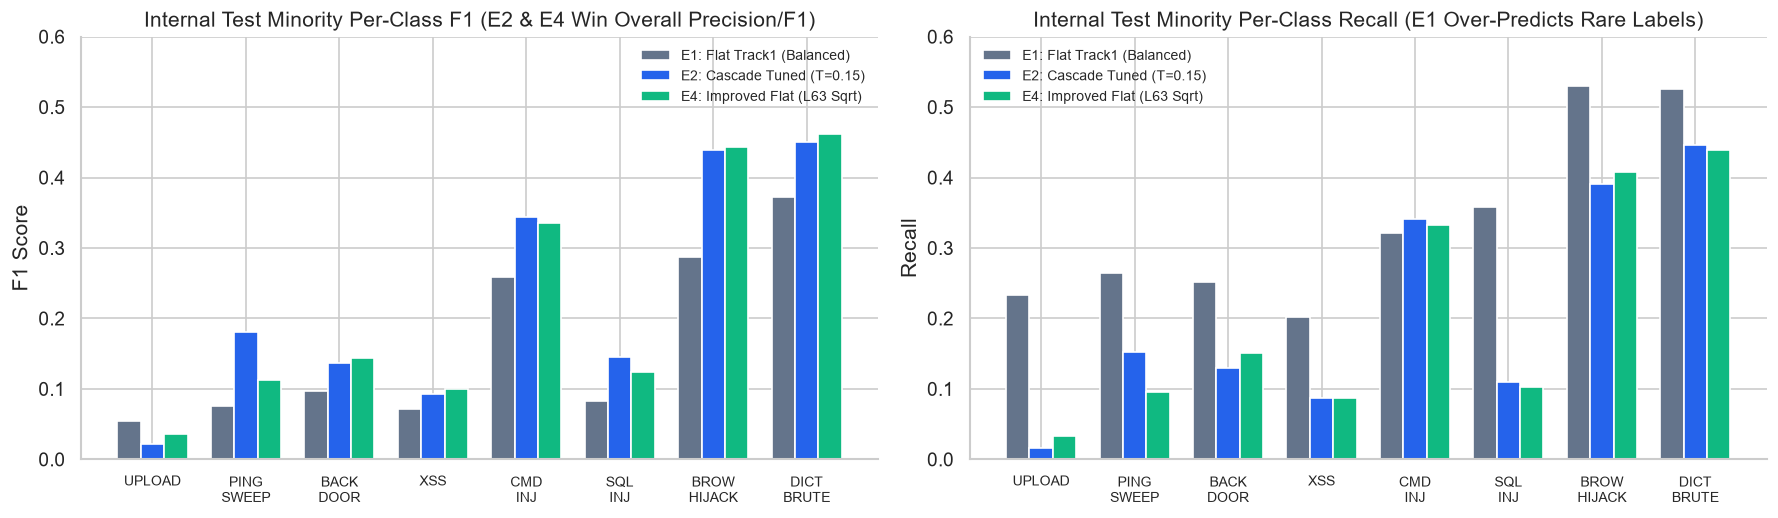

Overall 8-Minority Mean on TEST  : {'E1: Flat Track1 (Balanced)': (np.float64(0.1624), np.float64(0.336)), 'E2: Cascade Tuned (T=0.15)': (np.float64(0.2264), np.float64(0.2094)), 'E4: Improved Flat (L63 Sqrt)': (np.float64(0.2196), np.float64(0.2063))}
Overall 8-Minority Mean on CROSS : {'E1: Flat Track1 (Balanced)': (np.float64(0.3142), np.float64(0.3495)), 'E2: Cascade Tuned (T=0.15)': (np.float64(0.2954), np.float64(0.2214)), 'E4: Improved Flat (L63 Sqrt)': (np.float64(0.2872), np.float64(0.2184))}


In [6]:
df_min_test = pd.read_csv(HIER_RESULTS / "minority_attack_comparison_test.csv")
df_min_cross = pd.read_csv(HIER_RESULTS / "minority_attack_comparison_cross.csv")

min_sub_t = df_min_test[df_min_test["architecture"].isin([MAIN_ORDER[0], MAIN_ORDER[2], MAIN_ORDER[3]])].set_index("architecture")
f1_cols = [f"{c}_f1" for c in MINORITY_ATTACK_CLASSES]
rec_cols = [f"{c}_recall" for c in MINORITY_ATTACK_CLASSES]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

xm = np.arange(len(MINORITY_ATTACK_CLASSES))
wm = 0.25
for idx, arch in enumerate([MAIN_ORDER[0], MAIN_ORDER[2], MAIN_ORDER[3]]):
    lbl = ARCH_LABELS[arch]
    axes[0].bar(xm + (idx - 1) * wm, min_sub_t.loc[arch, f1_cols].values, width=wm, color=PALETTE[lbl], label=lbl)
    axes[1].bar(xm + (idx - 1) * wm, min_sub_t.loc[arch, rec_cols].values, width=wm, color=PALETTE[lbl], label=lbl)

short_names = ["UPLOAD", "PING\nSWEEP", "BACK\nDOOR", "XSS", "CMD\nINJ", "SQL\nINJ", "BROW\nHIJACK", "DICT\nBRUTE"]
for ax, title, ylabel in [
    (axes[0], "Internal Test Minority Per-Class F1 (E2 & E4 Win Overall Precision/F1)", "F1 Score"),
    (axes[1], "Internal Test Minority Per-Class Recall (E1 Over-Predicts Rare Labels)", "Recall"),
]:
    ax.set_xticks(xm)
    ax.set_xticklabels(short_names, fontsize=8.5)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 0.60)
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=8.5)

plt.tight_layout()
plt.show()

print("Overall 8-Minority Mean on TEST  :", {ARCH_LABELS[a]: (round(min_sub_t.loc[a, 'minority_macro_f1'], 4), round(min_sub_t.loc[a, 'minority_macro_recall'], 4)) for a in min_sub_t.index})
min_sub_c = df_min_cross[df_min_cross["architecture"].isin([MAIN_ORDER[0], MAIN_ORDER[2], MAIN_ORDER[3]])].set_index("architecture")
print("Overall 8-Minority Mean on CROSS :", {ARCH_LABELS[a]: (round(min_sub_c.loc[a, 'minority_macro_f1'], 4), round(min_sub_c.loc[a, 'minority_macro_recall'], 4)) for a in min_sub_c.index})

---
### Appendix Note: Why Parallel Specialist Fusion Without a Stage 2 Router (E3) Failed
Even though our core research focus is **E1 vs. E2 vs. E4**, we briefly ran the negative ablation **E3** (running Stage 3A Flood and Stage 3B Non-Flood in parallel without Stage 2) and observed a key failure mode:
- Because each specialist only sees its own family during training, **`E3_Parallel_NaiveMax` collapsed to `56.11%` Test Accuracy / `0.4389` Macro-F1** — on **76.16%** (`52,083`) of passed Test attacks, *both* specialists output confidence `>= 0.50` simultaneously (`26,678` cross-family errors!).
- A learned Logistic Regression gate (`E3_Parallel_MetaGate`) recovered Test Accuracy to **`73.78%` (`0.6239` Macro-F1)**, still behind both **E2 (`0.6361`)** and **E4 (`0.6352`)** — confirming why you should not run closed-world specialists in parallel without either a Stage 2 raw-feature router or a unified flat classifier.

---
### Final Track 2 Recommendation
- **Primary Deployment Choice → [`e4_lgbm_leaves63_sqrt.joblib`](../track2_ids_engineering/hierarchical_ids/models/e4_lgbm_leaves63_sqrt.joblib)**: Highest Test (`75.37%`) and Cross-Capture (`70.72%`) Accuracy and MCC, ties E2 Macro-F1 (`0.6352` vs `0.6361`), **1.0 execution/flow**, and **~4.15 ms** single-flow latency.
- **Modular Policy Choice → `E2_Cascade_ValTuned`**: Useful when you need separate sensitivity thresholds per tier (and replace Stage 1 RF `n_jobs=-1` with LightGBM for low single-flow latency).